# Benchmark: carga y espacio de las estrategias de k-mers

**Responsable:** Juan Arias

**Objetivo:** comparar la estrategia principal (colección `kmers`, MODELO.md) con la alternativa embebida
(`tes_embebidos`) en tiempo de carga y espacio en disco. Los tiempos vienen de `03_pipeline_kmers.ipynb`
(`resultados/benchmark_carga.csv`). El benchmark de consultas está en `06_benchmark.ipynb` (Thomas).

Modelo de referencia: `../MODELO.md`

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from pymongo import MongoClient

sys.path.insert(0, "..")
from src.benchmark import guardar_benchmark

DB_NAME = "panteon"
RESULTADOS = Path("../resultados")
FIGURAS = Path("../figuras")
FIGURAS.mkdir(exist_ok=True)

client = MongoClient("mongodb://localhost:27017")
db = client[DB_NAME]
db_bench = client[f"{DB_NAME}_bench"]

## 1. Tiempos de carga

In [2]:
carga = pd.read_csv(RESULTADOS / "benchmark_carga.csv")
carga = carga[carga["base"].isin([DB_NAME, db_bench.name])
              & carga["estrategia"].isin(["coleccion_kmers", "embebido_en_tes"])].reset_index(drop=True)
assert len(carga) == 2, f"Faltan filas de {DB_NAME} en benchmark_carga.csv: ejecutar 03_pipeline_kmers.ipynb"
carga["t_total_s"] = carga[["t_calculo_s", "t_insercion_s", "t_indices_s"]].sum(axis=1)
carga

,estrategia,base,n_tes,n_docs,t_calculo_s,t_insercion_s,t_indices_s,t_total_s
0,coleccion_kmers,panteon,239946,1439676,123.379,49.782,25.079,198.240
1,embebido_en_tes,panteon_bench,239946,239946,136.123,45.746,11.998,193.867


## 2. Espacio (`collStats`)

In [3]:
def estadisticas(base, coleccion, estrategia):
    st = base.command("collStats", coleccion)
    fila = {
        "estrategia": estrategia, "base": base.name, "coleccion": coleccion,
        "count": st["count"], "size": st["size"], "avgObjSize": st.get("avgObjSize", 0),
        "storageSize": st["storageSize"], "totalIndexSize": st["totalIndexSize"],
    }
    fila.update({f"idx_{nombre}": tam for nombre, tam in st["indexSizes"].items()})
    return fila


espacio = pd.DataFrame([
    estadisticas(db, "kmers", "coleccion_kmers"),
    estadisticas(db_bench, "tes_embebidos", "embebido_en_tes"),
    estadisticas(db, "tes", "referencia_tes"),
])
guardar_benchmark(espacio.to_dict("records"), RESULTADOS / "benchmark_espacio.csv")
espacio.T

,0,1,2
estrategia,coleccion_kmers,embebido_en_tes,referencia_tes
base,panteon,panteon_bench,panteon
coleccion,kmers,tes_embebidos,tes
count,1439676,239946,239946
size,8144577956,8104036854,73969252
avgObjSize,5657,33774,308
storageSize,3180089344,3184513024,12718080
totalIndexSize,60604416,5398528,10919936
idx__id_,15917056,2453504,2404352
idx_te_id_1_k_1,16445440.0,NaN,NaN


`size` es el tamaño sin comprimir de los documentos; `storageSize` es lo que ocupan en disco con la compresión de WiredTiger. Todos los tamaños están en bytes. `tes` es solo referencia: la estrategia embebida contiene una copia de `tes` más los k-mers.

## 3. Figuras

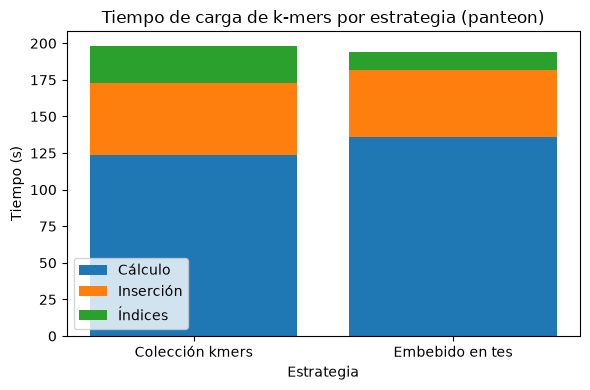

In [4]:
NOMBRES = {"coleccion_kmers": "Colección kmers", "embebido_en_tes": "Embebido en tes", "referencia_tes": "tes (referencia)"}

fig, ax = plt.subplots(figsize=(6, 4))
etiquetas = carga["estrategia"].map(NOMBRES)
abajo = 0
for columna, nombre in [("t_calculo_s", "Cálculo"), ("t_insercion_s", "Inserción"), ("t_indices_s", "Índices")]:
    ax.bar(etiquetas, carga[columna], bottom=abajo, label=nombre)
    abajo = abajo + carga[columna]
ax.set_title(f"Tiempo de carga de k-mers por estrategia ({DB_NAME})")
ax.set_xlabel("Estrategia")
ax.set_ylabel("Tiempo (s)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURAS / f"benchmark_carga_{DB_NAME}.png", dpi=300)
plt.show()

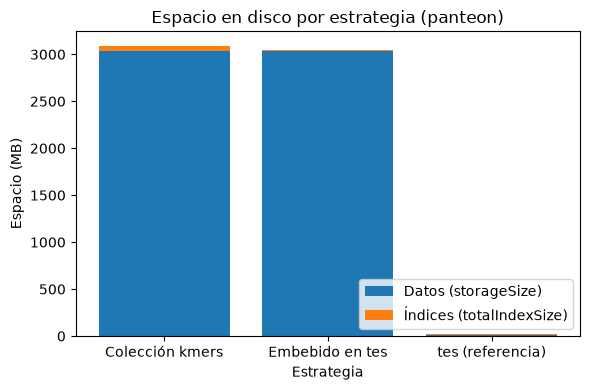

In [5]:
MB = 1024 ** 2
fig, ax = plt.subplots(figsize=(6, 4))
etiquetas = espacio["estrategia"].map(NOMBRES)
ax.bar(etiquetas, espacio["storageSize"] / MB, label="Datos (storageSize)")
ax.bar(etiquetas, espacio["totalIndexSize"] / MB, bottom=espacio["storageSize"] / MB, label="Índices (totalIndexSize)")
ax.set_title(f"Espacio en disco por estrategia ({DB_NAME})")
ax.set_xlabel("Estrategia")
ax.set_ylabel("Espacio (MB)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURAS / f"benchmark_espacio_{DB_NAME}.png", dpi=300)
plt.show()

## 4. Interpretación

Cifras de `panteon` (239.946 TEs). Tamaños en MB de 1024² bytes; tiempos en segundos.

**Espacio en datos: prácticamente igual.** `kmers` ocupa 3.032,8 MB en disco (`storageSize`) y
`tes_embebidos` 3.037,0 MB; sin comprimir, 7.767,3 MB frente a 7.728,6 MB. La embebida incluye una copia de
`tes` (12,1 MB en disco), así que la parte de k-mers queda en unos 3.025 MB, apenas 0,3 % menos que `kmers`:
repetir `te_id`, `pdb_id`, `te_order` y `k` en 1,44 millones de documentos cuesta poco tras la compresión.

**Espacio en índices: `kmers` ocupa 11 veces más.** 57,8 MB (`_id` 15,2; `{te_id, k}` 15,7;
`{pdb_id, k}` 19,4; `{k, te_order}` 7,5) frente a 5,1 MB de `tes_embebidos` (`_id` 2,3; `{pdb_id}` 2,8),
porque indexa 1.439.676 entradas en lugar de 239.946. Aun así, los índices son menos del 2 % del total.

**Carga: casi empate.** `kmers` tarda 198,3 s (cálculo 123,4; inserción 49,8; índices 25,1) y la embebida
193,8 s (136,1; 45,7; 12,0). La embebida gana en índices y pierde en el armado de documentos, que copia cada
TE completo. La diferencia total es de 2 %, sin peso para decidir.

**Según el tipo de uso** (a confirmar con el benchmark de consultas de Thomas, `06_benchmark.ipynb`):

- **Un k para muchos TEs** (heatmap de 2-mers por orden, consultas sobre un solo k): favorece `kmers`. El
  índice `{k, te_order}` lleva directo a los documentos de ese k (5,7 KB de media entre todos los k). En la
  embebida cada TE es un documento de 33,8 KB de media y hay que leerlo entero aunque se proyecte solo `kmers.k2`.
- **Todos los k de un TE** (perfil completo, consulta 15): favorece la embebida, que lo resuelve con una sola
  lectura por `pdb_id`; en `kmers` son 6 documentos por `{pdb_id, k}`, igualmente rápido para un TE.

Con espacio y carga casi iguales, la elección la decide el patrón de consultas: si dominan las agregaciones
por k, como en el proyecto, conviene mantener la colección `kmers` de MODELO.md.

Las cifras de `panteon_prueba` (25 TEs) siguen en los CSV y solo sirvieron para validar el notebook.